# Biến đổi Fourier của tín hiệu liên tục

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dangquanghieu/tinhieu-hethong-notebooks/blob/main/notebooks/08_bien-doi-fourier-tin-hieu-lien-tuc.ipynb)

Notebook minh họa biến đổi Fourier (Fourier transform, FT) của tín hiệu liên tục: tính xấp xỉ FT bằng tích phân số, đối chiếu các cặp xung chữ nhật–sinc và xung Gauss (Gaussian pulse)–Gauss.

## Mục tiêu

- Hiểu $X(j\Omega)$ là biểu diễn tần số của tín hiệu liên tục $x(t)$.
- Phân biệt tần số góc liên tục $\Omega$ (rad/s), tần số $f$ (Hz) và tần số rời rạc $\omega$ (rad/mẫu).
- Tính xấp xỉ FT số bằng quy tắc hình thang `np.trapezoid`.
- Quan sát quan hệ thời gian–tần số qua cặp xung chữ nhật–sinc và xung Gauss–Gauss.
- Phân biệt FT liên tục không tuần hoàn nói chung với DTFT tuần hoàn theo $2\pi$.

## Tóm tắt lý thuyết

FT của tín hiệu liên tục được định nghĩa bởi

$$
X(j\Omega) := \int_{-\infty}^{\infty}x(t)e^{-j\Omega t}\,dt.
$$

Biến đổi Fourier ngược là

$$
x(t) = \frac{1}{2\pi}\int_{-\infty}^{\infty}X(j\Omega)e^{j\Omega t}\,d\Omega.
$$

Ở đây $\Omega$ có đơn vị rad/s và

$$
f=\frac{\Omega}{2\pi}
$$

có đơn vị Hz. Với tín hiệu liên tục, $X(j\Omega)$ không tuần hoàn nói chung. Điều này khác với DTFT của dãy rời rạc:

$$
X(e^{j\omega}) := \sum_{n=-\infty}^{\infty}x[n]e^{-j\omega n},
\qquad
X(e^{j(\omega+2\pi)})=X(e^{j\omega}).
$$

Hai cặp FT dùng trong notebook là

$$
\operatorname{rect}\left(\frac{t}{T}\right)
\overset{\operatorname{FT}}{\longleftrightarrow}
T\operatorname{sinc}\left(\frac{\Omega T}{2\pi}\right),
$$

$$
e^{-t^2/(2\sigma_t^2)}
\overset{\operatorname{FT}}{\longleftrightarrow}
\sqrt{2\pi}\sigma_t e^{-\sigma_t^2\Omega^2/2}.
$$

**Xem thêm:** Chương 3, *Biến đổi Fourier*; các nội dung về cặp biến đổi và phổ của các xung trong [giáo trình](https://github.com/dangquanghieu/book-thht).

## Bản đồ Python của notebook

Sinh viên chỉ cần chạy và đọc mã. Các mảng giá trị luôn đi kèm trục vật lý: `t` có đơn vị s, còn `Omega` có đơn vị rad/s. Chỉ số vị trí của phần tử trong mảng Python không thay thế cho các đại lượng này.

| Ý tưởng Python | Vai trò trong minh họa | Liên hệ với tín hiệu |
|---|---|---|
| `np.linspace` | tạo trục `t` và `Omega` | thời gian liên tục và tần số góc liên tục |
| `np.exp` | tạo hạt nhân Fourier phức | $e^{-j\Omega t}$ |
| broadcasting và `axis=0` | tạo tích phân cho mọi $\Omega$ | FT trên một lưới tần số |
| `np.trapezoid` | xấp xỉ tích phân | định nghĩa FT liên tục |
| `np.sinc` | tính sinc chuẩn hóa | $\sin(\pi u)/(\pi u)$ |
| `plot` | vẽ tín hiệu và phổ liên tục | $x(t)$, $|X(j\Omega)|$ |

### Khởi tạo: chỉ cần chạy

Cell này nạp NumPy và Matplotlib, định dạng hình, rồi định nghĩa hàm tính FT số dùng chung. Không cần phân tích chi tiết mã hạ tầng này.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "lines.linewidth": 2.0,
})


def continuous_ft(x_t, t, Omega):
    """Approximate X(jΩ) from x(t) with the trapezoidal integration rule."""
    integrand = x_t[:, None] * np.exp(-1j * t[:, None] * Omega[None, :])
    return np.trapezoid(integrand, x=t, axis=0)

## Minh họa 1: FT số là xấp xỉ một tích phân

Để tính FT bằng máy, ta giữ một miền thời gian hữu hạn $[t_{\min},t_{\max}]$ và thay tích phân bằng quy tắc hình thang:

$$
X(j\Omega)
\approx
\int_{t_{\min}}^{t_{\max}}x(t)e^{-j\Omega t}\,dt.
$$

Mỗi giá trị $\Omega$ cần một tích phân riêng. Code trong các minh họa sau tính nhiều tích phân đồng thời bằng broadcasting của NumPy.

**Python cần biết:** Với `t` gồm $N_t$ điểm và `Omega` gồm $N_\Omega$ điểm, `t[:, None]` có kích thước $(N_t,1)$, còn `Omega[None, :]` có kích thước $(1,N_\Omega)$. NumPy tạo mảng $(N_t,N_\Omega)$ chứa hạt nhân $e^{-j\Omega t}$. Sau đó `np.trapezoid(..., x=t, axis=0)` tích phân theo thời gian cho từng giá trị $\Omega$.

**Nhận xét:** Kết quả số phụ thuộc vào bước lưới thời gian và miền thời gian được giữ lại. Vì vậy, với mỗi ví dụ bên dưới, phổ số được đặt cạnh biểu thức giải tích để kiểm tra trực tiếp. Đây là phép tích phân số, không phải DFT hay FFT.

## Minh họa 2: Xung chữ nhật và sinc

Xét xung chữ nhật (rectangular pulse)

$$
x(t)=\operatorname{rect}\left(\frac{t}{T}\right).
$$

Ta thay đổi độ rộng $T$ và so sánh FT số với phổ sinc giải tích. Xung dài hơn theo thời gian có búp chính hẹp hơn theo tần số; phổ của xung chữ nhật cũng có các búp phụ.

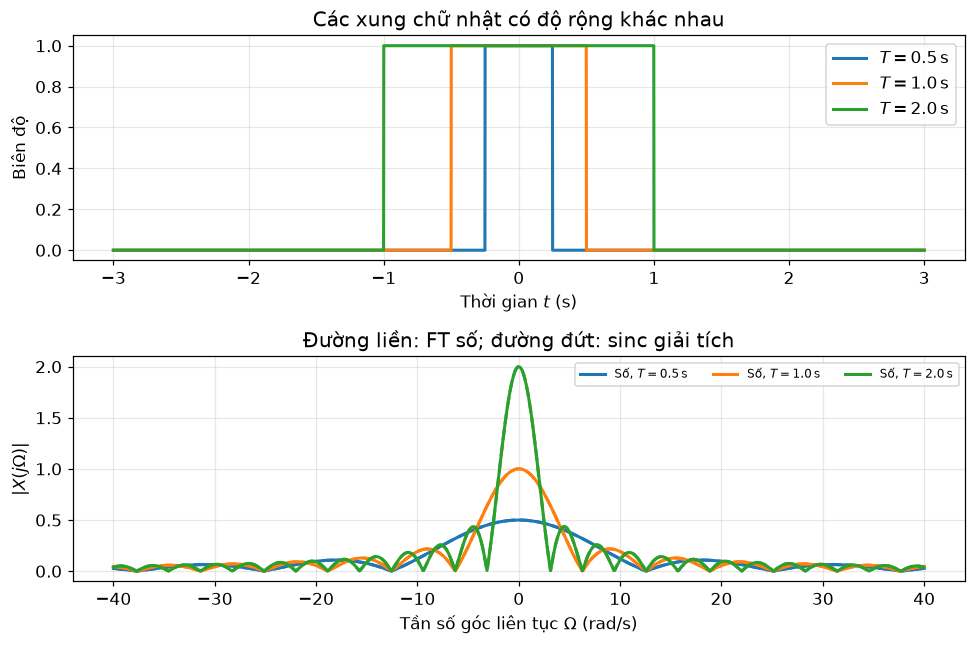

In [2]:
# Tạo các xung chữ nhật với ba độ rộng T.
t = np.linspace(-3.0, 3.0, 4_001)
Omega = np.linspace(-40.0, 40.0, 1_201)
widths = [0.5, 1.0, 2.0]

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=False)
for T in widths:
    x_rect = np.where(np.abs(t) <= T / 2, 1.0, 0.0)
    X_numeric = continuous_ft(x_rect, t, Omega)
    X_analytic = T * np.sinc(Omega * T / (2 * np.pi))

    axes[0].plot(t, x_rect, label=rf"$T={T:.1f}\,\mathrm{{s}}$")
    axes[1].plot(Omega, np.abs(X_numeric), label=rf"Số, $T={T:.1f}\,\mathrm{{s}}$")
    axes[1].plot(Omega, np.abs(X_analytic), "--", color=axes[1].lines[-1].get_color())

axes[0].set_xlabel("Thời gian $t$ (s)")
axes[0].set_ylabel("Biên độ")
axes[0].set_title("Các xung chữ nhật có độ rộng khác nhau")
axes[0].legend()
axes[1].set_xlabel(r"Tần số góc liên tục $\Omega$ (rad/s)")
axes[1].set_ylabel(r"$|X(j\Omega)|$")
axes[1].set_title("Đường liền: FT số; đường đứt: sinc giải tích")
axes[1].legend(ncol=3, fontsize=8)
fig.tight_layout()
plt.show()

**Nhận xét:** Khi $T$ tăng, búp chính quanh $\Omega=0$ hẹp lại. Các đường số và giải tích gần trùng nhau; sai khác nhỏ quanh các điểm không chủ yếu do xấp xỉ tích phân của xung có điểm gián đoạn. Búp phụ xuất hiện vì xung chữ nhật đổi giá trị đột ngột tại hai biên.

## Minh họa 3: Xung Gauss và phổ Gauss

Xét xung Gauss

$$
x(t)=e^{-t^2/(2\sigma_t^2)}.
$$

Không giống xung chữ nhật, xung Gauss trơn trên toàn bộ trục thời gian. Phổ của nó cũng có dạng Gauss, không có búp phụ. Ta thay đổi $\sigma_t$ để quan sát đánh đổi thời gian–tần số.

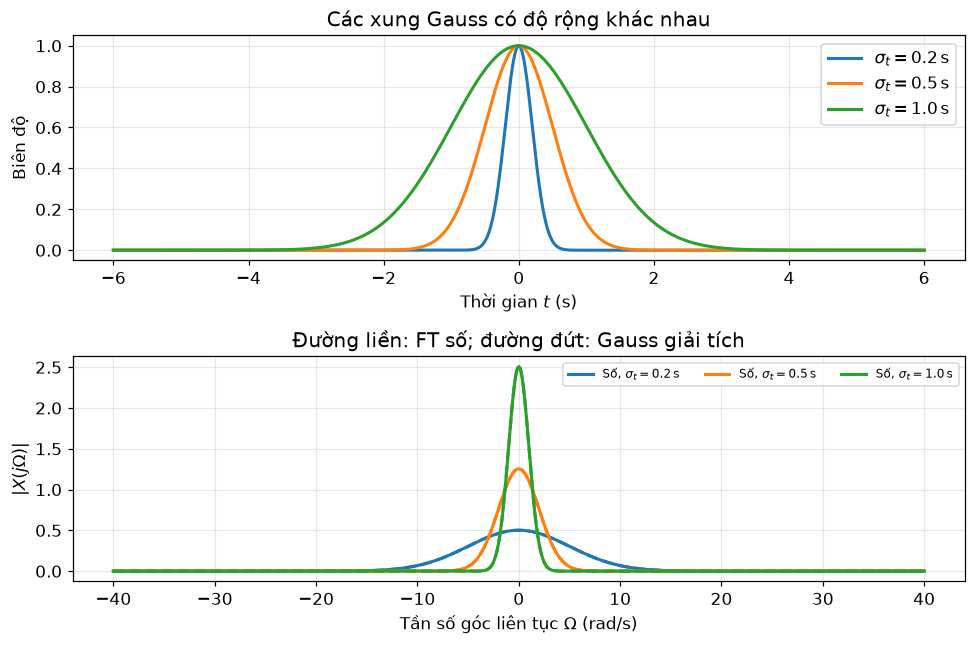

In [3]:
# Tạo các xung Gauss với ba độ rộng sigma_t.
t = np.linspace(-6.0, 6.0, 4_001)
Omega = np.linspace(-40.0, 40.0, 1_201)
sigmas = [0.2, 0.5, 1.0]

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=False)
for sigma_t in sigmas:
    x_gauss = np.exp(-t**2 / (2 * sigma_t**2))
    X_numeric = continuous_ft(x_gauss, t, Omega)
    X_analytic = np.sqrt(2 * np.pi) * sigma_t * np.exp(-sigma_t**2 * Omega**2 / 2)
    assert np.allclose(X_numeric, X_analytic, rtol=2e-3, atol=2e-4)

    axes[0].plot(t, x_gauss, label=rf"$\sigma_t={sigma_t:.1f}\,\mathrm{{s}}$")
    axes[1].plot(Omega, np.abs(X_numeric), label=rf"Số, $\sigma_t={sigma_t:.1f}\,\mathrm{{s}}$")
    axes[1].plot(Omega, X_analytic, "--", color=axes[1].lines[-1].get_color())

axes[0].set_xlabel("Thời gian $t$ (s)")
axes[0].set_ylabel("Biên độ")
axes[0].set_title("Các xung Gauss có độ rộng khác nhau")
axes[0].legend()
axes[1].set_xlabel(r"Tần số góc liên tục $\Omega$ (rad/s)")
axes[1].set_ylabel(r"$|X(j\Omega)|$")
axes[1].set_title("Đường liền: FT số; đường đứt: Gauss giải tích")
axes[1].legend(ncol=3, fontsize=8)
fig.tight_layout()
plt.show()

**Nhận xét:** Khi $\sigma_t$ tăng, xung Gauss rộng hơn theo thời gian và phổ hẹp hơn theo tần số. Khác với xung chữ nhật, xung Gauss và phổ của nó đều trơn; không xuất hiện búp phụ. Hai ví dụ cho thấy độ trơn của tín hiệu theo thời gian ảnh hưởng trực tiếp đến dạng phổ.

## Đối chiếu FT liên tục và DTFT

| Tín hiệu liên tục | Tín hiệu rời rạc |
|---|---|
| $x(t)$ | $x[n]$ |
| $X(j\Omega)$ | $X(e^{j\omega})$ |
| $\Omega$ tính bằng rad/s | $\omega$ tính bằng rad/mẫu |
| Không tuần hoàn nói chung theo $\Omega$ | Tuần hoàn theo $2\pi$ theo $\omega$ |
| Tính bằng tích phân | Tính bằng tổng |

Sự khác biệt về tính tuần hoàn là hệ quả của miền thời gian: biến $t$ liên tục không bị giới hạn vào các chỉ số nguyên, trong khi $n\in\mathbb{Z}$ làm $e^{-j(\omega+2\pi)n}=e^{-j\omega n}$.

## Cầu nối sang lấy mẫu

Nếu chỉ giữ các giá trị của tín hiệu liên tục tại những thời điểm cách đều nhau,

$$
x[n]=x(nT_s),
$$

thì tần số liên tục và tần số rời rạc liên hệ bởi

$$
\omega=\Omega T_s.
$$

Notebook tiếp theo sẽ khảo sát việc lấy mẫu làm phổ thay đổi thế nào, điều kiện để tái tạo tín hiệu và cách tránh chồng phổ.

## Câu hỏi suy ngẫm

1. Vì sao $X(j\Omega)$ không tuần hoàn nói chung, còn $X(e^{j\omega})$ tuần hoàn theo $2\pi$?
2. Khi tăng $T$ của xung chữ nhật, búp chính của phổ thay đổi thế nào?
3. Vì sao phổ của xung chữ nhật có búp phụ còn phổ Gauss không có?
4. Nếu giảm $\sigma_t$ của xung Gauss, phổ Gauss thay đổi ra sao?
5. Khi tính FT số bằng `np.trapezoid`, vì sao cần chọn cả bước lưới thời gian lẫn miền thời gian hữu hạn một cách phù hợp?